In [1]:
W = 4000

A = 8000 # simb/s
B = 6400 # simb/s
C = 8000 # simb/s

rA = 0
rB = 0.25
rC = 0.5

print("1. Revisión de las fichas\n")
print(f"La tasa máxima de símbolos sin ISI es de {W * 2} símbolos/s\n")
print("Por otra parte, la eficiencia espectral (empaquetamiento) de cada opción es de:")
print(f"A: {A/W} símbolos/s/Hz")
print(f"B: {B/W} símbolos/s/Hz")
print(f"C: {C/W} símbolos/s/Hz\n")

print("Ancho de banda por cada módem:")
print(f"W A = {int((1+rA)*A/2000)} kHz | Cabe en el canal")
print(f"W B = {int((1+rB)*B/2000)} kHz | Cabe en el canal")
print(f"W C = {int((1+rC)*C/2000)} kHz | No cabe en el canal\n")

print("En la práctica el módem A no es del todo posible, pues su r es un valor ideal\n")
W0 = B/2
BW_ex = W-W0 
print(f"Para B, su W0 es de {int(W0)} Hz, su ancho de banda excedente de {int(BW_ex)} Hz y su roll-off de {BW_ex/W0}")


1. Revisión de las fichas

La tasa máxima de símbolos sin ISI es de 8000 símbolos/s

Por otra parte, la eficiencia espectral (empaquetamiento) de cada opción es de:
A: 2.0 símbolos/s/Hz
B: 1.6 símbolos/s/Hz
C: 2.0 símbolos/s/Hz

Ancho de banda por cada módem:
W A = 4 kHz | Cabe en el canal
W B = 4 kHz | Cabe en el canal
W C = 6 kHz | No cabe en el canal

En la práctica el módem A no es del todo posible, pues su r es un valor ideal

Para B, su W0 es de 3200 Hz, su ancho de banda excedente de 800 Hz y su roll-off de 0.25


In [2]:
print("2. Diseño\n")
W0 = 5000/2
BW_ex = W-W0
print("Factor de roll-off: r:",BW_ex/W0,"\n")
print("La ventaja de un roll-off mayor es que facilita la transición de este y evita más el jitter,")
print("su desventaja es que requiere más espectro y bajar la tasa Rs.")

2. Diseño

Factor de roll-off: r: 0.6 

La ventaja de un roll-off mayor es que facilita la transición de este y evita más el jitter,
su desventaja es que requiere más espectro y bajar la tasa Rs.


3. Diagrama de ojo en Python



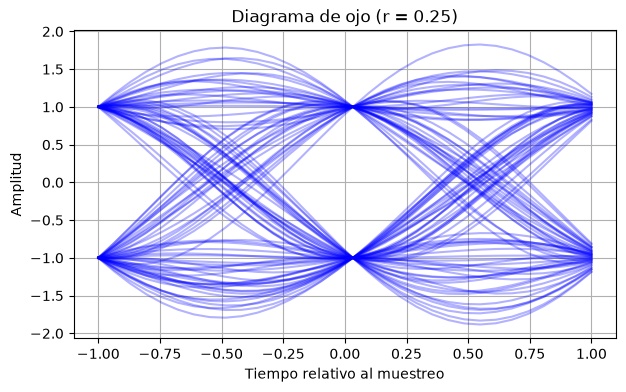

Resultados para r = 0.25:
Apertura en t = 0: 0.99999999992146
Apertura con atraso 0.25T: 0.22446730450754773



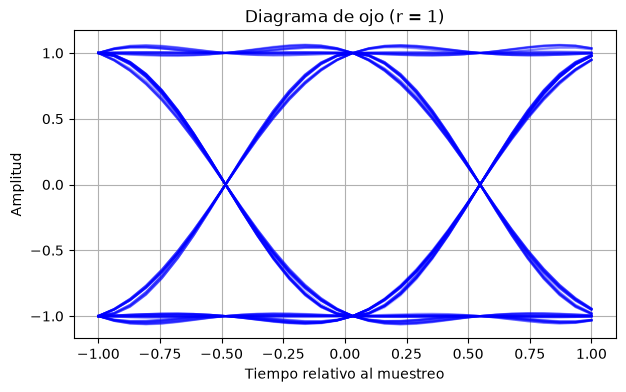

Resultados para r = 1:
Apertura en t = 0: 0.9999999999933333
Apertura con atraso 0.25T: 0.6382530972904092

Conclusión: El pulso con mayor roll-off (r = 1) tolera mejor los errores en el instante de muestreo (jitter).
Esto se debe a que un mayor roll-off suaviza las transiciones, manteniendo una mayor apertura de ojo desplazado 
respecto al centro.


In [11]:
print("3. Diagrama de ojo en Python\n")

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(666)

T = 1
num_symbols = 200
sps = 16
r = 0.25

W0 = 1/(2*T)
dif_W = r/(2*T)

t = np.linspace(-8*T, 8*T, 8*2*sps + 1)

denom = 1 - (4*dif_W*t)**2
t = np.where(np.abs(denom) < 1e-12, t + 1e-10, t)

denom = 1 - (4*dif_W*t)**2

sinc_val = np.sinc(t/T)
cos_val = np.cos(2*np.pi*dif_W*t)
p_t = (sinc_val*cos_val)/denom

symbols = np.random.choice([-1, 1], num_symbols)

upsampled = np.zeros(num_symbols*sps)

for i in range(num_symbols):
    upsampled[i*sps] = symbols[i]

signal = np.convolve(upsampled, p_t, mode='same')

for r_val in [0.25, 1]:
    dif_W = r_val/(2*T)
    denom = 1 - (4*dif_W*t)**2
    t_mod = np.where(np.abs(denom) < 1e-12, t + 1e-10, t)
    denom = 1 - (4*dif_W*t_mod)**2
    sinc_val = np.sinc(t_mod/T)
    cos_val = np.cos(2*np.pi*dif_W*t_mod)
    p_t = (sinc_val*cos_val)/denom
    signal_r = np.convolve(upsampled, p_t, mode='same')
    segment_len = 2*sps
    num_segments = len(signal_r) // segment_len
    t_axis = np.linspace(-T, T, segment_len)
    plt.figure(figsize=(7, 4))
    traces = []
    for i in range(1, num_segments - 1):

        inicio = i*segment_len - sps
        final = i*segment_len + sps
        seg = signal_r[inicio:final]
        if len(seg) == segment_len:
            plt.plot(t_axis, seg, color='blue', alpha=0.3)
            traces.append(seg)

    plt.title(f"Diagrama de ojo (r = {r_val})")
    plt.xlabel("Tiempo relativo al muestreo")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.show()

    traces = np.array(traces)

    center_idx = segment_len // 2
    offset_idx = int(0.25*sps)

    aper_centro = np.min(np.abs(traces[:, center_idx]))
    aper_atraso = np.min(np.abs(traces[:, center_idx + offset_idx]))

    print(f"Resultados para r = {r_val}:")
    print(f"Apertura en t = 0: {aper_centro}")
    print(f"Apertura con atraso 0.25T: {aper_atraso}\n")

print("Conclusión: El pulso con mayor roll-off (r = 1) tolera mejor los errores en el instante de muestreo (jitter).\n" \
"Esto se debe a que un mayor roll-off suaviza las transiciones, manteniendo una mayor apertura de ojo desplazado \n" \
"respecto al centro.")
